In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', 'NMT')
pth_out = os.path.join(pth_data, 'cancer', 'human', 'NMT')

In [3]:
fn = 'PDX63.strigentFilters_rmRibo_rmDoub.h5ad'
adata = sc.read_h5ad(os.path.join(pth_in, fn))
adata.obsm['X_pca'] = adata.obsm['PCA'].values.copy()
adata.obsm['X_umap'] = adata.obsm['UMAP'].values.copy()
del adata.obsm['PCA']; del adata.obsm['UMAP']; adata

AnnData object with n_obs × n_vars = 5837 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident'
    uns: 'X_name'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts'

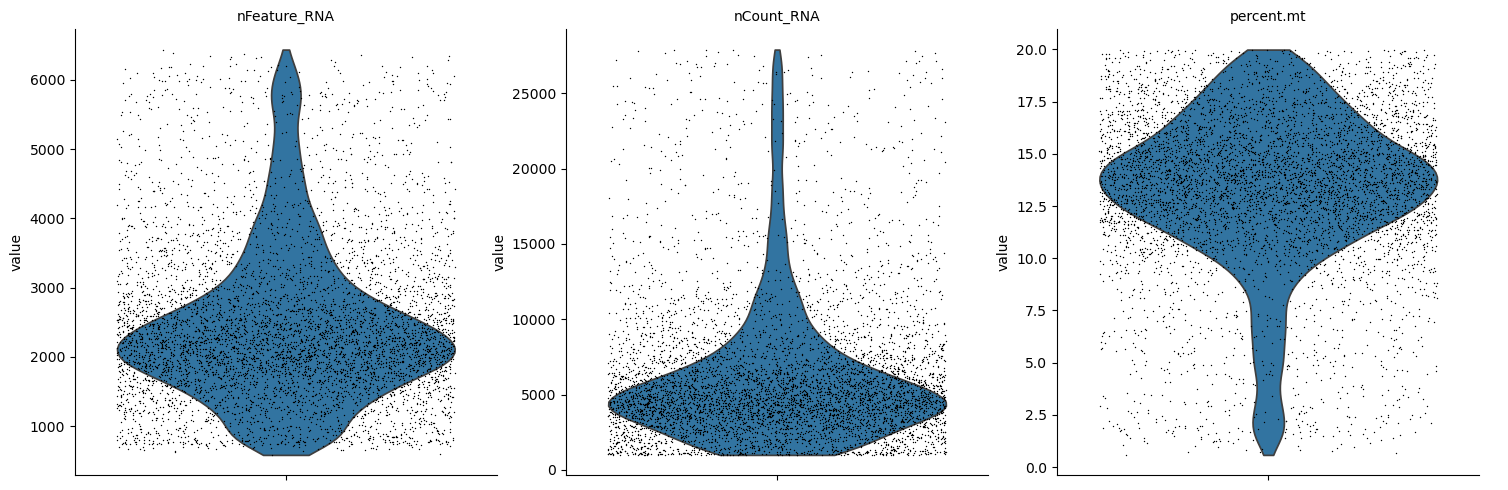

In [4]:
sc.pl.violin(adata, ['nFeature_RNA', 'nCount_RNA', 'percent.mt'], jitter = .4, multi_panel = True)

In [5]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

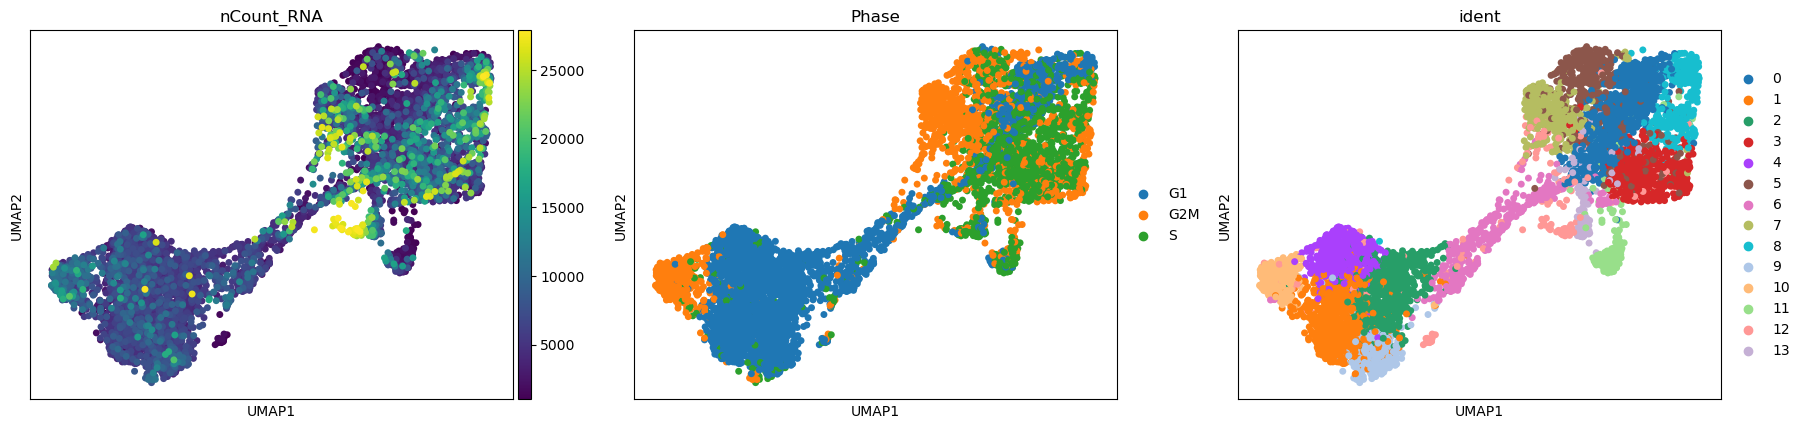

In [8]:
sc.pl.umap(adata, color = ['nCount_RNA', 'Phase', 'ident'], size = 100)

In [9]:
remove = ['10', '11', '12', '13']
adata = adata[~adata.obs.ident.isin(remove)].copy()
adata

AnnData object with n_obs × n_vars = 5101 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident'
    uns: 'X_name', 'log1p', 'ident_colors', 'Phase_colors'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts'

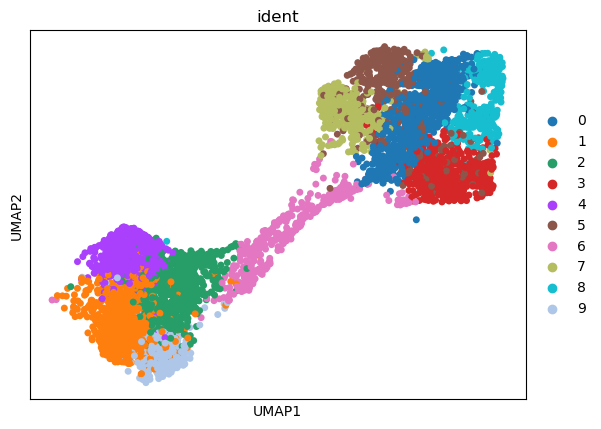

In [10]:
sc.pl.umap(adata, color = 'ident', size = 100)

In [11]:
celltype_dict = {
    '0' : 'NOR',
    '1' : 'MES',
    '2' : 'MES',
    '3' : 'NOR',
    '4' : 'MES',
    '5' : 'NOR',
    '6' : 'NOR/MES',
    '7' : 'NOR',
    '8' : 'NOR',
    '9' : 'MES'}

adata.obs['celltype'] = adata.obs.ident.map(celltype_dict).astype('category')

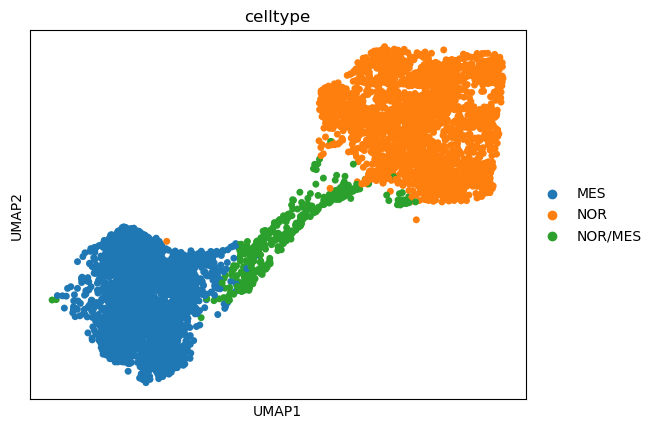

In [12]:
sc.pl.umap(adata, color = 'celltype', size = 100)

In [13]:
adata.write(os.path.join(pth_out, 'IC-pPDXC-63.h5ad'))